# Andy Trader: Can a Small PyTorch MLP Beat the Base Rate?

## Name: Dawn Andrei Pamesa
## Section: Paper Trading Research

Andy Trader logs paper predictions for BTC-USD and scores them. This notebook rebuilds its small PyTorch model step by
step and asks one question: can a small multilayer perceptron (MLP) predict whether the next 1 hour BTC-USD close is higher,
better than simply predicting the base rate? The judge is the **Brier skill score**, not accuracy. Brier skill is above
zero only when the probabilities beat the base rate; a hit rate can look fine while the probabilities are worse than
saying the usual share every time. This is paper trading research only. No money is involved.

In [1]:
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

# The notebook lives in research/, so the repository root has to be on the import path.
sys.path.append("..")
from andy_trader.model import FEATURE_NAMES, engineer_features
from andy_trader.store import default_database_path

Loading the Hourly Closes

In [2]:
database_path = default_database_path()
print("Database:", database_path)

Database: D:\Andy Trader\crypto_observations.db


In [3]:
connection = sqlite3.connect(f"file:{database_path.as_posix()}?mode=ro", uri=True)

In [4]:
# A fixed end time keeps every rerun on the same bars while the collector keeps writing.
end_time = "2026-11-17T00:00:00+00:00"

prices = pd.read_sql_query(
    "select open_time, close, last_seen_at from crypto_observations "
    "where instrument = 'BTC-USD' and venue = 'tradingview' and interval = '1h' "
    "and degraded = 0 and open_time < ? order by open_time, last_seen_at",
    connection,
    params=(end_time,),
)
print("Observations:", len(prices))

Observations: 4798


In [5]:
# An open bar is saved again each time its price changes, so keep the last value seen for each hour.
prices = prices.drop_duplicates("open_time", keep="last").reset_index(drop=True)
prices["open_time"] = pd.to_datetime(prices["open_time"], utc=True, format="ISO8601")
prices = prices[["open_time", "close"]]

print("Shape:", prices.shape)
prices.head()

Shape: (1838, 2)


,open_time,close
0,2026-09-01 10:00:00+00:00,78029.67
1,2026-09-01 11:00:00+00:00,78098.97
2,2026-09-01 12:00:00+00:00,78004.00
3,2026-09-01 13:00:00+00:00,78071.99
4,2026-09-01 14:00:00+00:00,78167.99


In [6]:
prices.describe()

,close
count,1838.000000
mean,79786.816012
std,4569.623951
min,62625.000000
25%,77320.480000
50%,80624.450000
75%,83162.802500
max,87166.950000


In [7]:
# The label is the next bar, so a missing hour would quietly pair two bars far apart.
prices["open_time"].diff().value_counts()

open_time
0 days 01:00:00    1837
Name: count, dtype: int64

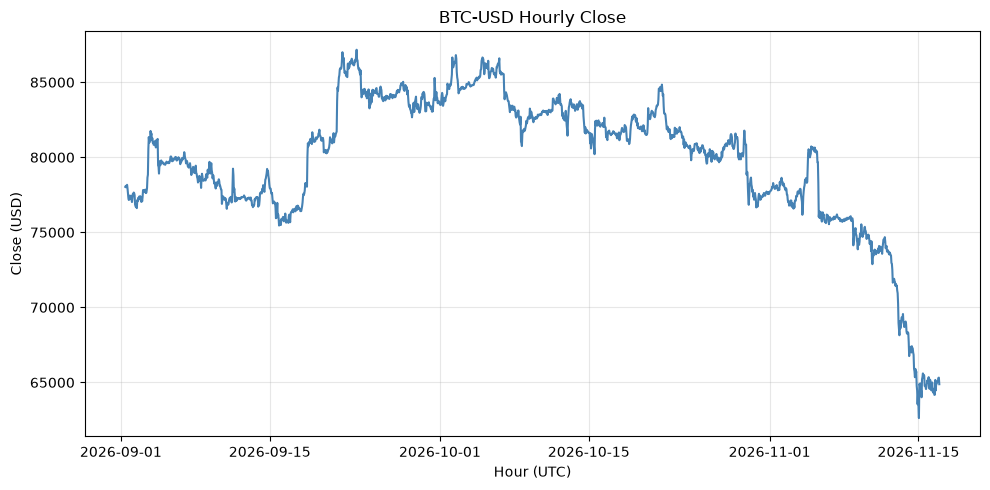

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(prices["open_time"], prices["close"], color="steelblue")
plt.xlabel("Hour (UTC)")
plt.ylabel("Close (USD)")
plt.title("BTC-USD Hourly Close")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Building the Features

In [9]:
# Each row uses only its own bar and the 24 bars before it.
rows = engineer_features(prices["close"].tolist())
X = pd.DataFrame([row.values for row in rows], columns=FEATURE_NAMES, index=[row.close_index for row in rows])

print("Shape:", X.shape)
X.head()

Shape: (1814, 6)


,return_1,return_3,return_6,mean_return,return_volatility,ema_12_distance
24,-0.000930,-0.010288,-0.011423,-0.000727,0.002687,-0.006724
25,0.001927,-0.000330,-0.010646,-0.000683,0.002721,-0.004085
26,-0.002801,-0.001805,-0.012938,-0.000749,0.002752,-0.005801
27,0.006921,0.006047,-0.004241,-0.000497,0.003139,0.000920
28,-0.001032,0.003089,0.002759,-0.000591,0.003119,-0.000114


In [10]:
X.describe()

,return_1,return_3,return_6,mean_return,return_volatility,ema_12_distance
count,1814.000000,1814.000000,1814.000000,1814.000000,1814.000000,1814.000000
mean,-0.000093,-0.000276,-0.000568,-0.000099,0.003488,-0.000520
std,0.003977,0.006817,0.009589,0.000826,0.001678,0.006281
min,-0.029273,-0.046668,-0.056782,-0.003608,0.000737,-0.041473
25%,-0.001595,-0.002853,-0.004423,-0.000508,0.002417,-0.003200
50%,-0.000048,-0.000074,-0.000046,-0.000039,0.003117,-0.000224
75%,0.001596,0.002633,0.003764,0.000285,0.004417,0.002341
max,0.035683,0.036251,0.046972,0.002931,0.011014,0.031821


Building the Label

In [11]:
# 1 when the next close is higher, 0 otherwise. A flat bar counts as 0, as in model.py.
next_close = prices["close"].shift(-1)
y = (next_close > prices["close"]).astype(int).loc[X.index].rename("next_bar_up")

In [12]:
# The newest bar has no next close yet, so it cannot be labelled.
X = X.iloc[:-1]
y = y.iloc[:-1]

print("Shape:", X.shape)
print("Labels:", y.shape)

Shape: (1813, 6)
Labels: (1813,)


In [13]:
y.value_counts()

next_bar_up
0    924
1    889
Name: count, dtype: int64

In [14]:
print("Share of Up Bars:", round(y.mean(), 4))

Share of Up Bars: 0.4903


Chronological Split

In [15]:
# No shuffling. The newest 20 percent is the test set, so the model never learns from bars after it.
test_count = len(X) // 5
X_rest, X_test = X.iloc[:-test_count], X.iloc[-test_count:]
y_rest, y_test = y.iloc[:-test_count], y.iloc[-test_count:]

In [16]:
# As in model.py, the newest 20 percent of what is left is kept back for calibration.
calibration_count = len(X_rest) // 5
X_train, X_cal = X_rest.iloc[:-calibration_count], X_rest.iloc[-calibration_count:]
y_train, y_cal = y_rest.iloc[:-calibration_count], y_rest.iloc[-calibration_count:]

print("Training set:", X_train.shape, " Calibration set:", X_cal.shape, " Test set:", X_test.shape)

Training set: (1161, 6)  Calibration set: (290, 6)  Test set: (362, 6)


In [17]:
print("Training:", prices["open_time"][X_train.index[0]], "to", prices["open_time"][X_train.index[-1]])
print("Calibration:", prices["open_time"][X_cal.index[0]], "to", prices["open_time"][X_cal.index[-1]])
print("Test:", prices["open_time"][X_test.index[0]], "to", prices["open_time"][X_test.index[-1]])

Training: 2026-09-02 10:00:00+00:00 to 2026-10-20 18:00:00+00:00
Calibration: 2026-10-20 19:00:00+00:00 to 2026-11-01 20:00:00+00:00
Test: 2026-11-01 21:00:00+00:00 to 2026-11-16 22:00:00+00:00


In [18]:
print("Share of Up Bars, Training:", round(y_train.mean(), 4))
print("Share of Up Bars, Calibration:", round(y_cal.mean(), 4))
print("Share of Up Bars, Test:", round(y_test.mean(), 4))

Share of Up Bars, Training: 0.5039
Share of Up Bars, Calibration: 0.4897
Share of Up Bars, Test: 0.4475


Standardising the Features

In [19]:
# Mean and scale come from the training set only, so nothing from later bars leaks in.
# ddof=0 matches the population standard deviation in model.py.
means = X_train.mean()
scales = X_train.std(ddof=0).clip(lower=1e-8)

X_train_scaled = (X_train - means) / scales
X_cal_scaled = (X_cal - means) / scales
X_test_scaled = (X_test - means) / scales

In [20]:
print("Before Scaling:")
print(X_train.describe().loc[["mean", "std"]].round(4))
print()
print("After Scaling:")
print(X_train_scaled.describe().loc[["mean", "std"]].round(2))

Before Scaling:
      return_1  return_3  return_6  mean_return  return_volatility  \
mean    0.0001    0.0002    0.0003       0.0000             0.0032   
std     0.0036    0.0062    0.0086       0.0007             0.0013   

      ema_12_distance  
mean           0.0003  
std            0.0057  

After Scaling:
      return_1  return_3  return_6  mean_return  return_volatility  \
mean       0.0       0.0       0.0         -0.0               -0.0   
std        1.0       1.0       1.0          1.0                1.0   

      ema_12_distance  
mean              0.0  
std               1.0  


In [21]:
X_train_t = torch.tensor(X_train_scaled.values, dtype=torch.float32)
X_cal_t = torch.tensor(X_cal_scaled.values, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_cal_t = torch.tensor(y_cal.values, dtype=torch.float32).reshape(-1, 1)

print("X_train_t:", X_train_t.shape, " y_train_t:", y_train_t.shape)
print("X_cal_t:", X_cal_t.shape, " y_cal_t:", y_cal_t.shape)
print("X_test_t:", X_test_t.shape)

X_train_t: torch.Size([1161, 6])  y_train_t: torch.Size([1161, 1])
X_cal_t: torch.Size([290, 6])  y_cal_t: torch.Size([290, 1])
X_test_t: torch.Size([362, 6])


Building the Model

In [22]:
torch.manual_seed(1729)
torch.use_deterministic_algorithms(True)

# The same shape as TorchPredictor: 6 features, 8 tanh units, 1 output logit.
model = nn.Sequential(
    nn.Linear(len(FEATURE_NAMES), 8),
    nn.Tanh(),
    nn.Linear(8, 1),
)
model

Sequential(
  (0): Linear(in_features=6, out_features=8, bias=True)
  (1): Tanh()
  (2): Linear(in_features=8, out_features=1, bias=True)
)

In [23]:
print("Trainable Parameters:", sum(p.numel() for p in model.parameters()))

Trainable Parameters: 65


In [24]:
# BCEWithLogitsLoss takes the raw logit, so the model has no sigmoid layer of its own.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.BCEWithLogitsLoss()

Training the Model

In [25]:
# 40 full-batch steps at a learning rate of 0.01, the TorchPredictor defaults.
losses = []
model.train()
for epoch in range(40):
    optimizer.zero_grad()
    loss = loss_fn(model(X_train_t), y_train_t)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print("First Loss:", round(losses[0], 4))
print("Last Loss:", round(losses[-1], 4))
print("Coin Flip Loss (ln 2):", round(np.log(2), 4))

First Loss: 0.701
Last Loss: 0.6874
Coin Flip Loss (ln 2): 0.6931


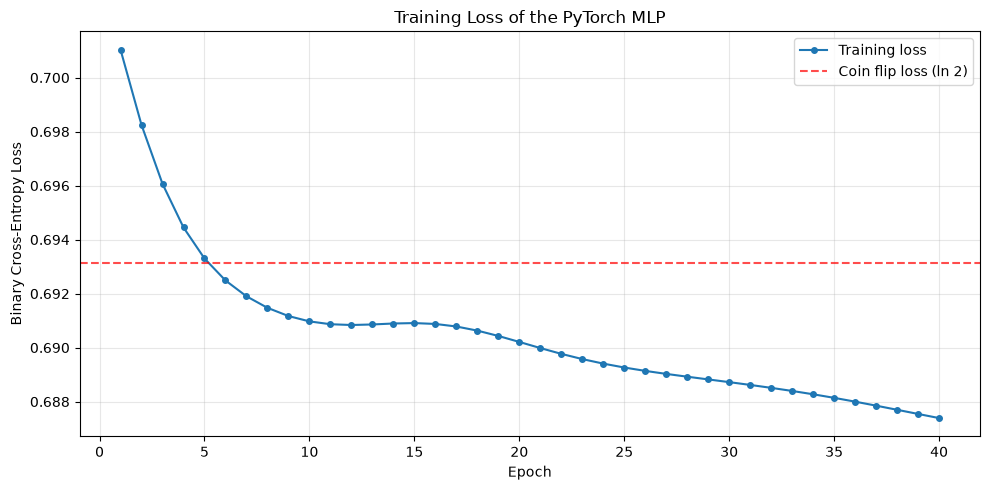

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(losses) + 1), losses, marker="o", markersize=4, label="Training loss")
plt.axhline(np.log(2), color="red", linestyle="--", alpha=0.7, label="Coin flip loss (ln 2)")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss of the PyTorch MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Calibrating with Temperature Scaling

In [27]:
model.eval()
with torch.no_grad():
    cal_logits = model(X_cal_t)

In [28]:
# One temperature divides every logit. It changes how confident the model is, never which way it calls.
# It is fitted on the calibration set only, never on the test set.
log_temperature = torch.zeros(1, requires_grad=True)
temperature_optimizer = torch.optim.Adam([log_temperature], lr=0.05)
for step in range(60):
    temperature_optimizer.zero_grad()
    temperature = torch.exp(log_temperature).clamp(0.1, 10.0)
    cal_loss = loss_fn(cal_logits / temperature, y_cal_t)
    cal_loss.backward()
    temperature_optimizer.step()
    with torch.no_grad():
        log_temperature.clamp_(np.log(0.1), np.log(10.0))

temperature = torch.exp(log_temperature.detach()).clamp(0.1, 10.0).item()
print("Temperature:", round(temperature, 4))

Temperature: 1.8784


In [29]:
print("Calibration Loss Before:", round(loss_fn(cal_logits, y_cal_t).item(), 4))
print("Calibration Loss After:", round(loss_fn(cal_logits / temperature, y_cal_t).item(), 4))

Calibration Loss Before: 0.693
Calibration Loss After: 0.6921


Predicting the Test Set

In [30]:
with torch.no_grad():
    test_logits = model(X_test_t)
y_prob = torch.sigmoid(test_logits / temperature).numpy().ravel()

print("Test Predictions:", len(y_prob))
print("Lowest Probability of Up:", round(y_prob.min(), 4))
print("Highest Probability of Up:", round(y_prob.max(), 4))

Test Predictions: 362
Lowest Probability of Up: 0.4342
Highest Probability of Up: 0.5954


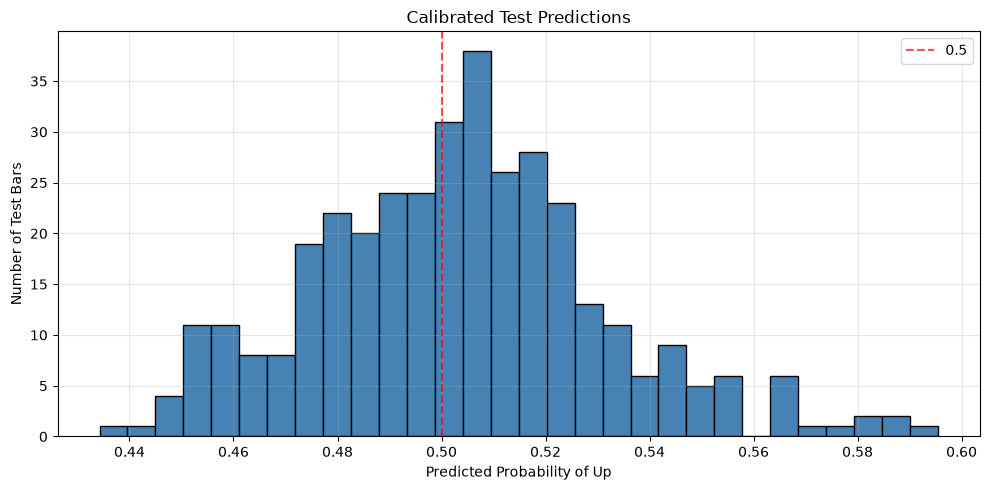

In [31]:
plt.figure(figsize=(10, 5))
plt.hist(y_prob, bins=30, color="steelblue", edgecolor="black")
plt.axvline(0.5, color="red", linestyle="--", alpha=0.7, label="0.5")
plt.xlabel("Predicted Probability of Up")
plt.ylabel("Number of Test Bars")
plt.title("Calibrated Test Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Scoring the Model

In [32]:
brier = np.mean((y_prob - y_test.values) ** 2)
print("Brier Score, MLP:", round(brier, 4))

Brier Score, MLP: 0.2505


In [33]:
# The reference says the test set's own up share every time. That share is known only in hindsight,
# so it is a slightly harder bar than any real base rate predictor, as in calibration.py.
base_rate = y_test.mean()
brier_reference = np.mean((base_rate - y_test.values) ** 2)

print("Base Rate of the Test Set:", round(base_rate, 4))
print("Brier Score, Base Rate:", round(brier_reference, 4))

Base Rate of the Test Set: 0.4475
Brier Score, Base Rate: 0.2472


In [34]:
brier_skill = 1 - brier / brier_reference
print("Brier Skill:", round(brier_skill, 4))

Brier Skill: -0.0132


In [35]:
y_pred = (y_prob > 0.5).astype(int)
hit_rate = np.mean(y_pred == y_test.values)

print("Share of Up Calls:", round(y_pred.mean(), 4))
print("Hit Rate: {:.4f}  ({:.1f}%)".format(hit_rate, hit_rate * 100))
print("Hit Rate of Always Calling Down: {:.4f}  ({:.1f}%)".format(1 - base_rate, (1 - base_rate) * 100))

Share of Up Calls: 0.5552
Hit Rate: 0.5110  (51.1%)
Hit Rate of Always Calling Down: 0.5525  (55.2%)


Comparing with the Baselines

In [36]:
coin_flip_prob = np.full(len(y_test), 0.5)
training_rate_prob = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "predictor": ["PyTorch MLP", "Coin flip", "Base rate from training", "Base rate of test (reference)"],
    "brier": [
        brier,
        np.mean((coin_flip_prob - y_test.values) ** 2),
        np.mean((training_rate_prob - y_test.values) ** 2),
        brier_reference,
    ],
})
results["brier_skill"] = 1 - results["brier"] / brier_reference
results.round(4)

,predictor,brier,brier_skill
0,PyTorch MLP,0.2505,-0.0132
1,Coin flip,0.2500,-0.0111
2,Base rate from training,0.2504,-0.0128
3,Base rate of test (reference),0.2472,0.0000


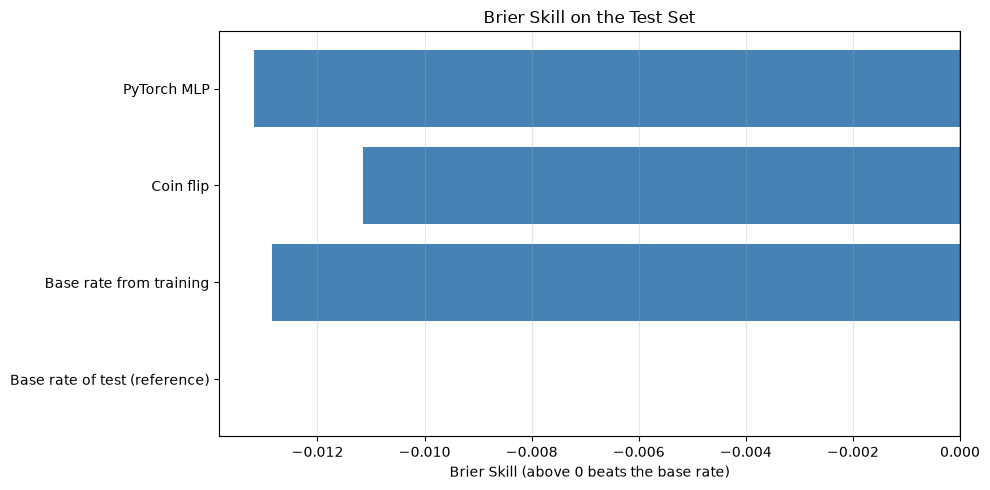

In [37]:
plt.figure(figsize=(10, 5))
plt.barh(results["predictor"][::-1], results["brier_skill"][::-1], color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Brier Skill (above 0 beats the base rate)")
plt.title("Brier Skill on the Test Set")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Checking the Calibration

In [38]:
# Ten equal bins from 0 to 1, left edge included, as in calibration.py.
reliability_table = pd.DataFrame({"probability": y_prob, "outcome": y_test.values})
reliability_table["bin"] = pd.cut(reliability_table["probability"], bins=np.linspace(0, 1, 11), right=False)

reliability_bins = reliability_table.groupby("bin", observed=True).agg(
    count=("outcome", "size"),
    mean_probability=("probability", "mean"),
    observed_rate=("outcome", "mean"),
)
reliability_bins.round(4)

,count,mean_probability,observed_rate
bin,,,
"[0.4, 0.5)",161,0.4791,0.4286
"[0.5, 0.6)",201,0.5228,0.4627


In [39]:
# Murphy's reliability term: the count-weighted squared gap between what was said and what happened. 0 is perfect.
gaps = reliability_bins["mean_probability"] - reliability_bins["observed_rate"]
reliability = (reliability_bins["count"] * gaps ** 2).sum() / len(y_test)
print("Reliability:", round(reliability, 4))

Reliability: 0.0031


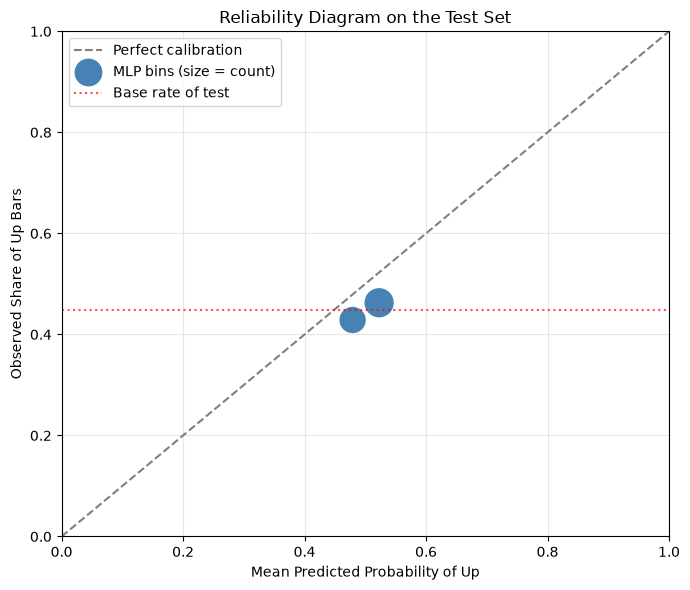

In [40]:
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
plt.scatter(reliability_bins["mean_probability"], reliability_bins["observed_rate"],
            s=reliability_bins["count"] * 2, color="steelblue", label="MLP bins (size = count)")
plt.axhline(base_rate, color="red", linestyle=":", alpha=0.7, label="Base rate of test")
plt.xlabel("Mean Predicted Probability of Up")
plt.ylabel("Observed Share of Up Bars")
plt.title("Reliability Diagram on the Test Set")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
connection.close()

Wrap-Up

**The small PyTorch MLP did not beat the base rate.** On the 362 test bars, from 2026-11-01 21:00 to 2026-11-16 22:00 UTC,
its Brier score was 0.2505 against 0.2472 for the base rate, a Brier skill of -0.0132. It also scored worse than the coin
flip, which says 0.5 every time and scored 0.2500 (skill -0.0111), and worse than the base rate learned from the training
set, which scored 0.2504 (skill -0.0128).

The training loss fell from 0.701 to 0.6874, just under the coin flip loss of 0.6931, but that small fit to the training
bars did not carry over to later bars. Temperature scaling on the calibration set set the temperature to 1.8784, which
softened every prediction to between 0.4342 and 0.5954. The reliability term was 0.0031, so the probabilities were close
to calibrated, but they carried no useful information: the share of up bars in the test set was 0.4475, while the MLP
called up on 0.5552 of them, so it leaned the wrong way.

The hit rate shows why accuracy is the wrong judge. The MLP was right 51.1 percent of the time, which sounds better than a
coin, yet always calling down would have been right 55.2 percent of the time on the same bars, and the MLP still lost on
Brier skill.

This agrees with the repository. Its walk-forward backtest over 120 windows gave the MLP a Brier skill of -0.0354, a
reliability of 0.0143 and a 40.8 percent hit rate, and the promotion gate rejected the first candidate. The numbers here
differ because this notebook uses one chronological split, not 120 refits.

What would have to change before claiming skill:

- Positive Brier skill on a test slice the model has never seen, and a win over the base rate predictor on that same slice,
  which is what the promotion gate asks for.
- The result holding across many walk-forward windows and several seeds, not one split and seed 1729.
- Enough test bars that the gap is larger than chance; 362 bars and Brier scores of 0.2505 against 0.2472 cannot show it.
- Features that carry information the six trailing price features do not. With these features the network had nothing to learn.
- For trading, a profit after fees and slippage, which is a higher bar than Brier skill.